(sec-2)=
# 2. Análisis exploratorio de datos

En esta sección se audita el conjunto de datos para tomar decisiones de modelado. Cada análisis cierra con la decisión de preprocesamiento que deriva, el impacto en la arquitectura y los riesgos, incluidas las posibles fuentes de fuga de datos. El conjunto de prueba se define en la sección {ref}`2.1.3 <sec-2-1-3>`, se congela con su suma SHA-256 y, desde ese punto, no se usa su etiqueta ni para diseñar el preprocesamiento ni para ajustar hiperparámetros.

(sec-2-1)=
## 2.1 EDA general

(sec-2-1-1)=
### 2.1.1 Variable objetivo

Se cuantifica el desbalance con la razón entre la clase mayoritaria y la minoritaria, y con la entropía de la distribución, $H = -\sum_c p_c \log_2 p_c$.

Clase,Flujos,%
Blackhole,26110,"21,37"
Flooding,19726,"16,15"
Normal,26172,"21,42"
Sybil,24077,"19,71"
Wormhole,26086,"21,35"


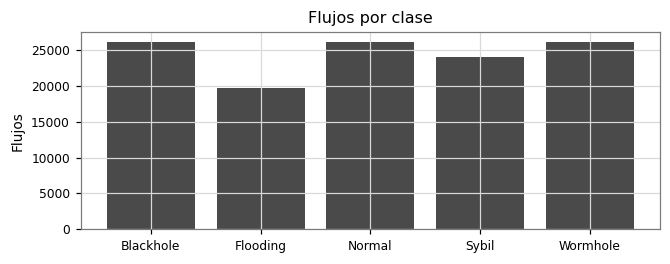

**Interpretación.** Normal es la clase mayoritaria, con 21,4 %, y Flooding la minoritaria, con 16,1 %, para una razón de 1,33 a 1. La entropía es de 2,314 bits frente a un máximo de $\log_2 5$ = 2,322 bits, es decir, el 99,7 % de la incertidumbre de un reparto uniforme.

Esto significa que no hay clases raras y que el desbalance es leve. Un clasificador trivial que responda siempre la clase mayoritaria tendría un F1 macro de 0,071, porque su F1 es cero en las otras cuatro clases, y ese es el piso real de comparación.

Por tal motivo, se conservan todas las clases, sin remuestrear, y se pondera la entropía cruzada, con pesos que se calculan después de eliminar las filas repetidas, porque esa limpieza cambia las proporciones, como muestra la sección {ref}`2.1.2 <sec-2-1-2>`.

**Decisión de preprocesamiento.** No se elimina ni se duplica ninguna muestra por desbalance; los pesos de clase se calculan solo con entrenamiento en la sección {ref}`2.2.5 <sec-2-2-5>`.

**Impacto en la arquitectura.** La capa de salida tiene 5 neuronas con entropía cruzada ponderada, y la selección de modelos se hace con F1 macro.

**Riesgos.** La proporción de clases es una decisión de quien construyó el archivo, no una frecuencia real de ataques. Por ello, las métricas no anticipan el desempeño en una red donde los ataques sean raros.

In [5]:
conteo = np.bincount(y, minlength=K)
p = conteo / conteo.sum()
razon = conteo.max() / conteo.min()
entropia = float(-(p * np.log2(p)).sum())
display(pd.DataFrame({"Clase": CLASES, "Flujos": conteo, "%": 100 * p}).style.hide(axis="index").format({"%": "{:.2f}"}))
fig, eje = plt.subplots(figsize=(6.2, 2.5))
eje.bar(CLASES, conteo, color=GRIS_OSCURO)
eje.set(ylabel="Flujos", title="Flujos por clase")
plt.tight_layout()
plt.show()
f1_trivial = (2 * p.max() / (1 + p.max())) / K
interpretar(f'''**Interpretación.** {CLASES[int(conteo.argmax())]} es la clase mayoritaria, con {num(100 * p.max(), 1)} %, y {CLASES[int(conteo.argmin())]} la minoritaria, con {num(100 * p.min(), 1)} %, para una razón de {num(razon, 2)} a 1. La entropía es de {num(entropia, 3)} bits frente a un máximo de $\\log_2 {K}$ = {num(np.log2(K), 3)} bits, es decir, el {num(100 * entropia / np.log2(K), 1)} % de la incertidumbre de un reparto uniforme.

Esto significa que no hay clases raras y que el desbalance es leve. Un clasificador trivial que responda siempre la clase mayoritaria tendría un F1 macro de {num(f1_trivial, 3)}, porque su F1 es cero en las otras cuatro clases, y ese es el piso real de comparación.

Por tal motivo, se conservan todas las clases, sin remuestrear, y se pondera la entropía cruzada, con pesos que se calculan después de eliminar las filas repetidas, porque esa limpieza cambia las proporciones, como muestra la sección 2.1.2.

**Decisión de preprocesamiento.** No se elimina ni se duplica ninguna muestra por desbalance; los pesos de clase se calculan solo con entrenamiento en la sección 2.2.5.

**Impacto en la arquitectura.** La capa de salida tiene {K} neuronas con entropía cruzada ponderada, y la selección de modelos se hace con F1 macro.

**Riesgos.** La proporción de clases es una decisión de quien construyó el archivo, no una frecuencia real de ataques. Por ello, las métricas no anticipan el desempeño en una red donde los ataques sean raros.''')

(sec-2-1-2)=
### 2.1.2 Calidad del dataset

Se buscan valores faltantes, explícitos o disfrazados, datos fuera de rango físico, inconsistencias entre atributos y duplicados. Los casi duplicados se buscan redondeando el logaritmo de cada atributo a dos decimales, lo que equivale a una diferencia de cerca de 1 %, y el ruido de etiquetas se estima con los grupos de flujos idénticos o casi idénticos que tienen clases distintas.

In [6]:
nulos = int(datos.isna().sum().sum())
no_finitos = int((~np.isfinite(x_crudo)).sum())
negativos = int((x_crudo < 0).sum())
constantes = [c for c in datos.columns if datos[c].nunique() == 1]
rx_mayor = int((datos["RxPackets"] > datos["TxPackets"]).sum())
perdidos_distintos = int((datos["LostPackets"] != datos["TxPackets"] - datos["RxPackets"]).sum())
tasa_fuera = int((datos["PacketDropRate"] > 1).sum())
sin_recepcion = (datos["RxPackets"] == 0).to_numpy()
retardo_nulo = int(((datos["MeanDelay/s"] == 0) & sin_recepcion).sum())
tabla_rx = pd.crosstab(nombre_clase, sin_recepcion).reindex(CLASES)
chi_rx = stats.chi2_contingency(tabla_rx.to_numpy())
v_rx = cramer(tabla_rx.to_numpy())
display(pd.DataFrame({"Revisión": ["Valores nulos", "Valores no finitos", "Valores negativos", "Columnas constantes", "RxPackets mayor que TxPackets", "LostPackets distinto de TxPackets - RxPackets", "PacketDropRate mayor que 1", "Flujos sin ningún paquete recibido", "De ellos, con retardo igual a 0"],
                      "Resultado": [nulos, no_finitos, negativos, ", ".join(constantes) or "ninguna", rx_mayor, perdidos_distintos, tasa_fuera, int(sin_recepcion.sum()), retardo_nulo]}).style.hide(axis="index"))
display((100 * tabla_rx[True] / tabla_rx.sum(axis=1)).round(2).rename("% de flujos sin recepción").to_frame().T)

repetidas = datos[ATRIBUTOS + ["label"]].duplicated()
sin_flowid = datos.drop(columns="FlowID").duplicated()
repetidas_clase = pd.DataFrame({"Clase": CLASES, "Flujos": conteo, "Filas repetidas": np.bincount(y[repetidas.to_numpy()], minlength=K)})
repetidas_clase["% de la clase"] = 100 * repetidas_clase["Filas repetidas"] / repetidas_clase["Flujos"]
repetidas_clase["% del archivo sin repetidas"] = 100 * (repetidas_clase["Flujos"] - repetidas_clase["Filas repetidas"]) / (N - repetidas.sum())
display(repetidas_clase.style.hide(axis="index").format({"% de la clase": "{:.1f}", "% del archivo sin repetidas": "{:.1f}"}))
exactas_trafico = datos[ATRIBUTOS].duplicated(keep=False)
conflictos_exactos = int((datos[exactas_trafico].groupby(ATRIBUTOS)["label"].nunique() > 1).sum())
casi = pd.DataFrame(np.round(np.log1p(x_crudo), 2))
huella = pd.util.hash_pandas_object(casi, index=False)
grupos_casi = pd.DataFrame({"huella": huella.to_numpy(), "clase": y})
resumen_casi = grupos_casi.groupby("huella")["clase"].agg(["size", "nunique"])
en_grupo_casi = resumen_casi.loc[resumen_casi["size"] > 1]
conflictos_casi = int((en_grupo_casi["nunique"] > 1).sum())
filas_conflicto = int(en_grupo_casi.loc[en_grupo_casi["nunique"] > 1, "size"].sum())
display(pd.DataFrame({"Revisión": ["Filas repetidas sin contar FlowID", "Filas repetidas en los atributos de tráfico, con la misma etiqueta", "Grupos idénticos en tráfico con más de una clase", "Filas en grupos de casi duplicados", "Grupos de casi duplicados", "Grupos de casi duplicados con más de una clase", "Filas en esos grupos"],
                      "Resultado": [int(sin_flowid.sum()), int(repetidas.sum()), conflictos_exactos, int(en_grupo_casi["size"].sum()), len(en_grupo_casi), conflictos_casi, filas_conflicto]}).style.hide(axis="index"))

Revisión,Resultado
Valores nulos,0
Valores no finitos,0
Valores negativos,0
Columnas constantes,Protocol
RxPackets mayor que TxPackets,0
LostPackets distinto de TxPackets - RxPackets,24554
PacketDropRate mayor que 1,81
Flujos sin ningún paquete recibido,30
"De ellos, con retardo igual a 0",30


label,Blackhole,Flooding,Normal,Sybil,Wormhole
% de flujos sin recepción,0,"0,15",0,0,0


Clase,Flujos,Filas repetidas,% de la clase,% del archivo sin repetidas
Blackhole,26110,0,"0,0","22,9"
Flooding,19726,7950,"40,3","10,3"
Normal,26172,0,"0,0","23,0"
Sybil,24077,269,"1,1","20,9"
Wormhole,26086,0,"0,0","22,9"


Revisión,Resultado
Filas repetidas sin contar FlowID,8205
"Filas repetidas en los atributos de tráfico, con la misma etiqueta",8219
Grupos idénticos en tráfico con más de una clase,0
Filas en grupos de casi duplicados,33025
Grupos de casi duplicados,7932
Grupos de casi duplicados con más de una clase,187
Filas en esos grupos,547


In [7]:
clase_mas_rx = tabla_rx[True].div(tabla_rx.sum(axis=1)).idxmax()
pct_rx = 100 * sin_recepcion.mean()
fila_rep = repetidas_clase.loc[repetidas_clase["% de la clase"].idxmax()]
interpretar(f'''**Interpretación.** El archivo no tiene valores nulos ni no finitos, y ningún atributo es negativo, así que no hay faltantes explícitos. Sin embargo, {num(sin_recepcion.sum(), 0)} flujos, el {num(pct_rx, 2)} %, no recibieron ningún paquete, y en los {num(retardo_nulo, 0)} el retardo aparece como 0. Ese cero no es un retardo nulo, sino un valor no observado, es decir, un faltante disfrazado. Su mecanismo no es MCAR, porque todos están en {clase_mas_rx} (V de Cramér = {num(v_rx, 3)}, {valor_p(chi_rx[1])}), y corresponde a MNAR, ya que el retardo falta justamente porque ningún paquete llegó. Aun así, son tan pocos que su efecto es despreciable.

En cuanto a la consistencia, {num(tasa_fuera, 0)} flujos tienen una tasa de pérdida mayor que 1, imposible por definición, y en {num(perdidos_distintos, 0)} flujos los paquetes perdidos no coinciden con la diferencia entre enviados y recibidos, lo que indica que el simulador los contabiliza con otro criterio. Así mismo, al ignorar `FlowID` aparecen {num(repetidas.sum(), 0)} filas repetidas en los atributos de tráfico, todas con la misma etiqueta, concentradas en {fila_rep["Clase"]}, donde son el {num(fila_rep["% de la clase"], 1)} % de la clase. Es decir, al eliminarlas, esa clase pasa de {num(100 * p[CLASES.index(fila_rep["Clase"])], 1)} % a {num(fila_rep["% del archivo sin repetidas"], 1)} % del archivo. Además, hay {num(len(en_grupo_casi), 0)} grupos de casi duplicados, de los cuales {num(conflictos_casi, 0)} mezclan clases.

Hay que tener en cuenta que esos {num(conflictos_casi, 0)} grupos reúnen {num(filas_conflicto, 0)} filas, el {num(100 * filas_conflicto / N, 1)} % del archivo, y que se toman como una cota del ruido de etiquetas: son flujos casi iguales con distinta etiqueta, lo que apunta a tráfico sin relación con el ataque que recibe la etiqueta de su escenario. Esto significa que el F1 macro no puede llegar a 1 aunque el modelo sea perfecto.

**Decisión de preprocesamiento.** Se eliminan las filas repetidas antes de partir, se recorta `PacketDropRate` a 1 y se conserva el cero del retardo, porque la falta de recepción se expresa también en `RxPackets`. Los casi duplicados se conservan, porque son flujos cortos y parecidos, propios del tráfico, y su efecto sobre la partición se mide en la sección 2.1.3.

**Impacto en la arquitectura.** Ninguno en la estructura. La reducción de {fila_rep["Clase"]} sí aumenta su peso en la pérdida, como se calcula en la sección 2.2.5.

**Riesgos.** Una fila repetida en entrenamiento y en prueba sería fuga directa, y por eso se elimina. El ruido de etiquetas no se puede corregir, porque el archivo no permite saber qué flujos participan en el ataque.''')

**Interpretación.** El archivo no tiene valores nulos ni no finitos, y ningún atributo es negativo, así que no hay faltantes explícitos. Sin embargo, 30 flujos, el 0,02 %, no recibieron ningún paquete, y en los 30 el retardo aparece como 0. Ese cero no es un retardo nulo, sino un valor no observado, es decir, un faltante disfrazado. Su mecanismo no es MCAR, porque todos están en Flooding (V de Cramér = 0,036, p < 0,001), y corresponde a MNAR, ya que el retardo falta justamente porque ningún paquete llegó. Aun así, son tan pocos que su efecto es despreciable.

En cuanto a la consistencia, 81 flujos tienen una tasa de pérdida mayor que 1, imposible por definición, y en 24 554 flujos los paquetes perdidos no coinciden con la diferencia entre enviados y recibidos, lo que indica que el simulador los contabiliza con otro criterio. Así mismo, al ignorar `FlowID` aparecen 8 219 filas repetidas en los atributos de tráfico, todas con la misma etiqueta, concentradas en Flooding, donde son el 40,3 % de la clase. Es decir, al eliminarlas, esa clase pasa de 16,1 % a 10,3 % del archivo. Además, hay 7 932 grupos de casi duplicados, de los cuales 187 mezclan clases.

Hay que tener en cuenta que esos 187 grupos reúnen 547 filas, el 0,4 % del archivo, y que se toman como una cota del ruido de etiquetas: son flujos casi iguales con distinta etiqueta, lo que apunta a tráfico sin relación con el ataque que recibe la etiqueta de su escenario. Esto significa que el F1 macro no puede llegar a 1 aunque el modelo sea perfecto.

**Decisión de preprocesamiento.** Se eliminan las filas repetidas antes de partir, se recorta `PacketDropRate` a 1 y se conserva el cero del retardo, porque la falta de recepción se expresa también en `RxPackets`. Los casi duplicados se conservan, porque son flujos cortos y parecidos, propios del tráfico, y su efecto sobre la partición se mide en la sección {ref}`2.1.3 <sec-2-1-3>`.

**Impacto en la arquitectura.** Ninguno en la estructura. La reducción de Flooding sí aumenta su peso en la pérdida, como se calcula en la sección {ref}`2.2.5 <sec-2-2-5>`.

**Riesgos.** Una fila repetida en entrenamiento y en prueba sería fuga directa, y por eso se elimina. El ruido de etiquetas no se puede corregir, porque el archivo no permite saber qué flujos participan en el ataque.

(sec-2-1-3)=
### 2.1.3 Partición del dataset

La estrategia depende de la estructura de dependencia, así que primero se mide. Si las filas fueran independientes, cada clase ocuparía posiciones al azar en el archivo y dos filas vecinas se parecerían como dos filas cualesquiera. Para saberlo se mide cuántas filas vecinas comparten clase y la correlación de rangos de Spearman entre los atributos de filas de la misma clase separadas por distintos rezagos.

Clase,Rezago 1,Rezago 10,Rezago 100,Rezago 500,Rezago 1000,Rezago 2000,Rezago 5000
Blackhole,"0,565","0,401","0,212","0,156","0,115","0,085","0,098"
Flooding,"0,610","0,470","0,330","0,177","0,089","0,046","0,081"
Normal,"0,678","0,542","0,466","0,346","0,253","0,139","0,070"
Sybil,"0,830","0,827","0,608","0,374","0,122","0,147","0,141"
Wormhole,"0,684","0,632","0,594","0,522","0,462","0,365","0,333"


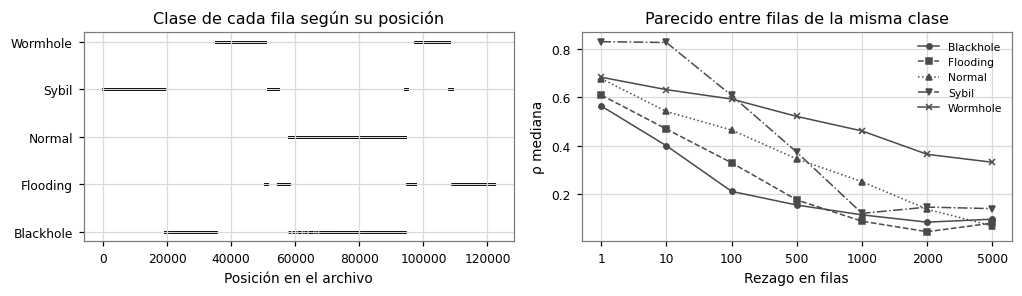

Mediana entre clases por rezago: {'Rezago 1': 0.678, 'Rezago 10': 0.542, 'Rezago 100': 0.466, 'Rezago 500': 0.346, 'Rezago 1000': 0.122, 'Rezago 2000': 0.139, 'Rezago 5000': 0.098}


**Interpretación.** El 93,0 % de las filas vecinas comparte clase, frente a 20,2 % bajo un orden aleatorio, y el tramo más largo de una sola clase tiene 19 180 filas. Además, entre filas de la misma clase, la ρ de Spearman mediana es de 0,678 en el rezago 1 y de 0,098 en el rezago 5000, frente a 0,000 con un orden aleatorio.

Esto significa que las filas no son independientes: el archivo conserva bloques de flujos muy parecidos, que sugieren un origen común en una misma simulación, aunque no trae el identificador que permitiría comprobarlo. Por eso, una partición aleatoria deja flujos casi gemelos en entrenamiento y en prueba, y mide en parte la capacidad de reconocer esa cercanía y no el ataque. Esa dependencia tampoco sigue a una entidad como el cliente: 125 de las 176 direcciones de origen aparecen en dos o más clases, y los tramos contiguos de una misma dirección tienen un largo mediano de 1 fila, de modo que agrupar por dirección no separaría a los flujos vecinos.

Por tal motivo, se declara la serie como unidad de independencia y, como el archivo no marca dónde empieza y termina cada una, se aproxima con una partición agrupada por bloques de filas contiguas, en la que un bloque completo queda en una sola partición.

**Decisión de preprocesamiento.** Cada fila se asigna a un bloque según su posición en el archivo, y los bloques se reparten entre las particiones, estratificando por clase.

**Impacto en la arquitectura.** Ninguno directo. La partición agrupada sí cambia el error con el que se comparan las arquitecturas, porque ahora mide la generalización a bloques no vistos.

**Riesgos.** El bloque es una aproximación, y no equivale a la simulación: los flujos a ambos lados del borde de un bloque siguen siendo parecidos, y un mismo escenario largo puede aportar bloques a varias particiones. Es decir, la partición agrupada reduce la fuga, pero no la elimina. Se declara como amenaza a la validez interna en la sección {ref}`5.5 <sec-5-5>`.

In [8]:
# Un tramo con un atributo constante no define ρ, y la mediana lo descarta
warnings.filterwarnings("ignore", category=stats.ConstantInputWarning)
vecinas = float((y[1:] == y[:-1]).mean())
azar_vecinas = float((p ** 2).sum())
tramos = pd.Series(y).ne(pd.Series(y).shift()).cumsum().value_counts()
REZAGOS = (1, 10, 100, 500, 1000, 2000, 5000)
x_log = np.log1p(x_crudo)
filas = []
for k, nombre in enumerate(CLASES):
    fila = {"Clase": nombre}
    pos = np.flatnonzero(y == k)
    for rezago in REZAGOS:
        a = pos[pos + rezago < N]
        a = a[y[a + rezago] == k]
        # Algunos atributos son constantes dentro de una clase: esos no aportan a la mediana
        rhos = [stats.spearmanr(x_log[a, j], x_log[a + rezago, j]).statistic for j in range(len(ATRIBUTOS)) if x_log[a, j].std() > 0 and x_log[a + rezago, j].std() > 0] if len(a) > 50 else []
        fila[f"Rezago {rezago}"] = float(np.nanmedian(rhos)) if rhos else np.nan
    filas.append(fila)
autocorrelacion = pd.DataFrame(filas)
display(autocorrelacion.style.hide(axis="index").format(precision=3, na_rep="sin pares"))
rng = np.random.default_rng(SEMILLA)
referencia = rng.permutation(N)
rho_azar = float(np.median([stats.spearmanr(x_log[:, j], x_log[referencia, j]).statistic for j in range(len(ATRIBUTOS))]))

fig, ejes = plt.subplots(1, 2, figsize=(9.4, 2.8))
ejes[0].scatter(np.arange(0, N, 15), y[::15], s=0.6, color=NEGRO)
ejes[0].set(yticks=range(K), yticklabels=CLASES, xlabel="Posición en el archivo", title="Clase de cada fila según su posición")
for fila, estilo in zip(autocorrelacion.to_dict("records"), [("-", "o"), ("--", "s"), (":", "^"), ("-.", "v"), ("-", "x")]):
    ejes[1].plot([str(r) for r in REZAGOS], [fila[f"Rezago {r}"] for r in REZAGOS], color=GRIS_OSCURO, linestyle=estilo[0], marker=estilo[1], markersize=3.5, linewidth=1, label=fila["Clase"])
ejes[1].set(xlabel="Rezago en filas", ylabel="ρ mediana", title="Parecido entre filas de la misma clase")
ejes[1].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()
mediana_por_rezago = autocorrelacion.drop(columns="Clase").median()
print("Mediana entre clases por rezago:", mediana_por_rezago.round(3).to_dict())
# Contraste con «cliente», la otra unidad de la lista del enunciado que podría aplicar
n_origenes = int(datos["SrcAddr"].nunique())
origenes_varias_clases = int((datos.groupby("SrcAddr")["label"].nunique() > 1).sum())
tramos_origen = datos["SrcAddr"].ne(datos["SrcAddr"].shift()).cumsum().value_counts()
interpretar(f'''**Interpretación.** El {num(100 * vecinas, 1)} % de las filas vecinas comparte clase, frente a {num(100 * azar_vecinas, 1)} % bajo un orden aleatorio, y el tramo más largo de una sola clase tiene {num(tramos.max(), 0)} filas. Además, entre filas de la misma clase, la ρ de Spearman mediana es de {num(mediana_por_rezago.iloc[0], 3)} en el rezago 1 y de {num(mediana_por_rezago.iloc[-1], 3)} en el rezago {REZAGOS[-1]}, frente a {num(abs(rho_azar), 3)} con un orden aleatorio.

Esto significa que las filas no son independientes: el archivo conserva bloques de flujos muy parecidos, que sugieren un origen común en una misma simulación, aunque no trae el identificador que permitiría comprobarlo. Por eso, una partición aleatoria deja flujos casi gemelos en entrenamiento y en prueba, y mide en parte la capacidad de reconocer esa cercanía y no el ataque. Esa dependencia tampoco sigue a una entidad como el cliente: {origenes_varias_clases} de las {n_origenes} direcciones de origen aparecen en dos o más clases, y los tramos contiguos de una misma dirección tienen un largo mediano de {num(tramos_origen.median(), 0)} fila, de modo que agrupar por dirección no separaría a los flujos vecinos.

Por tal motivo, se declara la serie como unidad de independencia y, como el archivo no marca dónde empieza y termina cada una, se aproxima con una partición agrupada por bloques de filas contiguas, en la que un bloque completo queda en una sola partición.

**Decisión de preprocesamiento.** Cada fila se asigna a un bloque según su posición en el archivo, y los bloques se reparten entre las particiones, estratificando por clase.

**Impacto en la arquitectura.** Ninguno directo. La partición agrupada sí cambia el error con el que se comparan las arquitecturas, porque ahora mide la generalización a bloques no vistos.

**Riesgos.** El bloque es una aproximación, y no equivale a la simulación: los flujos a ambos lados del borde de un bloque siguen siendo parecidos, y un mismo escenario largo puede aportar bloques a varias particiones. Es decir, la partición agrupada reduce la fuga, pero no la elimina. Se declara como amenaza a la validez interna en la sección 5.5.''')

In [9]:
LARGO_BLOQUE = 1000
RUTA_PARTICION = RESULTADOS / "particion.npz"
indices = np.flatnonzero(~datos[ATRIBUTOS + ["label"]].duplicated().to_numpy())
bloques = (datos["FlowID"].to_numpy() - 1) // LARGO_BLOQUE
if RUTA_PARTICION.exists():
    particion = np.load(RUTA_PARTICION)
    id_ent, id_val, id_pru = particion["entrenamiento"], particion["validacion"], particion["prueba"]
else:
    pos_resto, pos_pru = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEMILLA).split(indices, y[indices], bloques[indices]))
    id_pru, resto = indices[pos_pru], indices[pos_resto]
    pos_ent, pos_val = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEMILLA).split(resto, y[resto], bloques[resto]))
    id_ent, id_val = resto[pos_ent], resto[pos_val]
    np.savez(RUTA_PARTICION, entrenamiento=id_ent, validacion=id_val, prueba=id_pru)
assert not (set(bloques[id_ent]) & set(bloques[id_pru])) and not (set(bloques[id_ent]) & set(bloques[id_val])) and not (set(bloques[id_val]) & set(bloques[id_pru]))
SHA_PRUEBA = hashlib.sha256(np.sort(id_pru).tobytes()).hexdigest()
(RESULTADOS / "prueba.sha256").write_text(SHA_PRUEBA)
print("SHA-256 del conjunto de prueba:", SHA_PRUEBA)

PARTES = {"Entrenamiento": id_ent, "Validación": id_val, "Prueba": id_pru}
tabla_particion = pd.DataFrame({n: 100 * np.bincount(y[i], minlength=K) / len(i) for n, i in PARTES.items()}, index=CLASES)
tabla_particion.loc["Filas"] = [len(i) for i in PARTES.values()]
tabla_particion.loc["% del total"] = [100 * len(i) / len(indices) for i in PARTES.values()]
tabla_particion.loc["Bloques"] = [len(np.unique(bloques[i])) for i in PARTES.values()]
display(tabla_particion.round(2))
tabla_chi = np.array([np.bincount(y[i], minlength=K) for i in PARTES.values()])
chi_clase = stats.chi2_contingency(tabla_chi)
v_clase = cramer(tabla_chi)
brecha_clase = float(np.abs(tabla_particion.iloc[:K].sub(tabla_particion.iloc[:K].mean(axis=1), axis=0)).to_numpy().max())

ks = pd.Series({c: stats.ks_2samp(datos[c].to_numpy()[id_ent], datos[c].to_numpy()[id_pru]).statistic for c in ATRIBUTOS}).sort_values(ascending=False)
huellas_ent = set(huella.to_numpy()[id_ent])
casi_cruzan = float(np.mean([h in huellas_ent for h in huella.to_numpy()[id_pru]]))
exactas_cruzan = len(pd.merge(datos.iloc[id_ent][ATRIBUTOS], datos.iloc[id_pru][ATRIBUTOS], on=ATRIBUTOS, how="inner"))
print(f"Filas de prueba con un casi duplicado en entrenamiento: {100 * casi_cruzan:.1f} % | coincidencias exactas entre entrenamiento y prueba: {exactas_cruzan}")
interpretar(f'''**Interpretación.** Tras eliminar las filas repetidas quedan {num(len(indices), 0)} flujos, repartidos en bloques de {LARGO_BLOQUE} filas, porque en ese rezago la ρ mediana entre filas de la misma clase ya cayó a {num(mediana_por_rezago[f"Rezago {LARGO_BLOQUE}"], 3)}, sin dejar grupos tan grandes que la estratificación pierda sentido. Ningún bloque aparece en dos particiones. La proporción de clases {"difiere" if chi_clase[1] < 0.05 else "no difiere de forma significativa"} entre particiones ({valor_p(chi_clase[1])}), con un efecto de V de Cramér = {num(v_clase, 3)} y una brecha máxima de {num(brecha_clase, 2)} puntos porcentuales frente al promedio. En los atributos, la mayor distancia de Kolmogorov-Smirnov entre entrenamiento y prueba es de {num(ks.iloc[0], 3)}, en `{ks.index[0]}`.

Así mismo, el {num(100 * casi_cruzan, 1)} % de las filas de prueba tiene un casi duplicado en entrenamiento y hay {num(exactas_cruzan, 0)} coincidencias exactas, de modo que entre particiones casi no quedan flujos gemelos. Hay que tener en cuenta que eso no garantiza que una partición contenga solo simulaciones nuevas, porque el archivo no las identifica.

Por lo anterior, se conserva esta partición y se congela la prueba con su suma SHA-256.

**Decisión de preprocesamiento.** Partición estratificada por clase y agrupada por bloques, de 64, 16 y 20 %, con semilla {SEMILLA}, que se guarda en un archivo para reutilizarla en los Entregables 2 y 3.

**Impacto en la arquitectura.** Ninguno directo; todas las arquitecturas se comparan sobre las mismas particiones.

**Riesgos.** Con pocos bloques por clase, la composición de la prueba depende de qué bloques le tocaron. Por eso, la variabilidad entre semillas no incluye la de la partición, lo que se declara en la sección 7.''')

SHA-256 del conjunto de prueba: 2a2dab99c08ed1f19f24add07f5c6b0375e5ce0df7951a99090f54f4f2cd32b4


,Entrenamiento,Validación,Prueba
Blackhole,"23,67","22,07","21,15"
Flooding,"10,33","10,35","10,34"
Normal,"22,79","23,46","23,15"
Sybil,"20,59","21,65","21,27"
Wormhole,"22,62","22,47","24,09"
Filas,73267,17802,22883
% del total,"64,3","15,62","20,08"
Bloques,78,19,24


Filas de prueba con un casi duplicado en entrenamiento: 1.8 % | coincidencias exactas entre entrenamiento y prueba: 0


**Interpretación.** Tras eliminar las filas repetidas quedan 113 952 flujos, repartidos en bloques de 1000 filas, porque en ese rezago la ρ mediana entre filas de la misma clase ya cayó a 0,122, sin dejar grupos tan grandes que la estratificación pierda sentido. Ningún bloque aparece en dos particiones. La proporción de clases difiere entre particiones (p < 0,001), con un efecto de V de Cramér = 0,019 y una brecha máxima de 1,37 puntos porcentuales frente al promedio. En los atributos, la mayor distancia de Kolmogorov-Smirnov entre entrenamiento y prueba es de 0,128, en `TxPacketRate/s`.

Así mismo, el 1,8 % de las filas de prueba tiene un casi duplicado en entrenamiento y hay 0 coincidencias exactas, de modo que entre particiones casi no quedan flujos gemelos. Hay que tener en cuenta que eso no garantiza que una partición contenga solo simulaciones nuevas, porque el archivo no las identifica.

Por lo anterior, se conserva esta partición y se congela la prueba con su suma SHA-256.

**Decisión de preprocesamiento.** Partición estratificada por clase y agrupada por bloques, de 64, 16 y 20 %, con semilla 42, que se guarda en un archivo para reutilizarla en los Entregables 2 y 3.

**Impacto en la arquitectura.** Ninguno directo; todas las arquitecturas se comparan sobre las mismas particiones.

**Riesgos.** Con pocos bloques por clase, la composición de la prueba depende de qué bloques le tocaron. Por eso, la variabilidad entre semillas no incluye la de la partición, lo que se declara en la sección 7.

In [10]:
# Solo con entrenamiento y validación: el conjunto de prueba ya está congelado
id_dev = np.concatenate([id_ent, id_val])
x_dev = np.log1p(x_crudo)


def probar_boosting(columnas, ent, val):
    modelo = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA).fit(columnas[ent], y[ent])
    return f1_score(y[val], modelo.predict(columnas[val]), average="macro")


ent_azar, val_azar = train_test_split(id_dev, test_size=len(id_val), stratify=y[id_dev], random_state=SEMILLA)
f1_azar = probar_boosting(x_dev, ent_azar, val_azar)
f1_grupos = probar_boosting(x_dev, id_ent, id_val)
display(pd.DataFrame({"Partición de validación": ["Aleatoria estratificada, como en la literatura", f"Agrupada por bloques de {LARGO_BLOQUE} filas"], "F1 macro de referencia (boosting)": [f1_azar, f1_grupos]}).style.hide(axis="index").format({"F1 macro de referencia (boosting)": "{:.4f}"}))
filas_largo = []
for largo in (100, 500, 1000, 2000, 5000):
    grupos_dev = (datos["FlowID"].to_numpy()[id_dev] - 1) // largo
    valores = []
    for pos_a, pos_b in GroupShuffleSplit(3, test_size=0.2, random_state=SEMILLA).split(id_dev, groups=grupos_dev):
        modelo = HistGradientBoostingClassifier(max_iter=100, random_state=SEMILLA).fit(x_dev[id_dev[pos_a]], y[id_dev[pos_a]])
        valores.append(f1_score(y[id_dev[pos_b]], modelo.predict(x_dev[id_dev[pos_b]]), average="macro"))
    filas_largo.append({"Filas por bloque": largo, "Bloques": len(np.unique(grupos_dev)), "F1 macro medio": np.mean(valores), "Desviación entre particiones": np.std(valores, ddof=1)})
sensibilidad = pd.DataFrame(filas_largo)
display(sensibilidad.style.hide(axis="index").format({"F1 macro medio": "{:.4f}", "Desviación entre particiones": "{:.4f}"}))
interpretar(f'''**Interpretación.** Con el mismo modelo de referencia y los mismos atributos, el F1 macro de validación es de {num(f1_azar, 4)} con partición aleatoria y de {num(f1_grupos, 4)} con partición agrupada, una diferencia de {num(f1_azar - f1_grupos, 4)}. Al variar el largo del bloque dentro de entrenamiento y validación, con tres particiones por largo, el F1 macro medio va de {num(sensibilidad["F1 macro medio"].max(), 3)} a {num(sensibilidad["F1 macro medio"].min(), 3)}, y la desviación entre particiones llega a {num(sensibilidad["Desviación entre particiones"].max(), 3)}. Con los bloques más largos, esa desviación crece porque quedan muy pocos bloques y una partición puede quedarse casi sin una clase, y por eso no se usan.

Esto quiere decir que parte del desempeño de una partición aleatoria proviene de reconocer flujos vecinos en el archivo, y esa magnitud supera ampliamente el margen δ = 0,01. Por lo tanto, los valores de la literatura y los de este trabajo no son directamente comparables si la literatura usa partición aleatoria, lo que se examina en la sección 3.4.

En consecuencia, se decide reportar el baseline con la partición agrupada, por ser la que estima mejor la generalización a tráfico no visto.

**Decisión de preprocesamiento.** No agrega transformaciones: se conserva la partición por bloques definida arriba, y todo ajuste se hace solo con entrenamiento.

**Impacto en la arquitectura.** Ninguno en la estructura. Sí cambia la selección, porque las arquitecturas y los hiperparámetros se comparan solo con validación agrupada; una partición aleatoria favorecería a los modelos que reconocen flujos vecinos.

**Riesgos.** Esta diferencia se mide con un solo modelo de referencia y en validación, de modo que no se traslada exacta a las redes. Además, con los bloques más largos una partición puede quedarse casi sin una clase, lo que aumenta la varianza y es otra razón para no usarlos.''')

Partición de validación,F1 macro de referencia (boosting)
"Aleatoria estratificada, como en la literatura","0,9555"
Agrupada por bloques de 1000 filas,"0,8866"


Filas por bloque,Bloques,F1 macro medio,Desviación entre particiones
100,948,"0,9468","0,0031"
500,193,"0,8926","0,0577"
1000,97,"0,8913","0,0669"
2000,60,"0,8979","0,0561"
5000,25,"0,7638","0,1682"


**Interpretación.** Con el mismo modelo de referencia y los mismos atributos, el F1 macro de validación es de 0,9555 con partición aleatoria y de 0,8866 con partición agrupada, una diferencia de 0,0689. Al variar el largo del bloque dentro de entrenamiento y validación, con tres particiones por largo, el F1 macro medio va de 0,947 a 0,764, y la desviación entre particiones llega a 0,168. Con los bloques más largos, esa desviación crece porque quedan muy pocos bloques y una partición puede quedarse casi sin una clase, y por eso no se usan.

Esto quiere decir que parte del desempeño de una partición aleatoria proviene de reconocer flujos vecinos en el archivo, y esa magnitud supera ampliamente el margen δ = 0,01. Por lo tanto, los valores de la literatura y los de este trabajo no son directamente comparables si la literatura usa partición aleatoria, lo que se examina en la sección {ref}`3.4 <sec-3-4>`.

En consecuencia, se decide reportar el baseline con la partición agrupada, por ser la que estima mejor la generalización a tráfico no visto.

**Decisión de preprocesamiento.** No agrega transformaciones: se conserva la partición por bloques definida arriba, y todo ajuste se hace solo con entrenamiento.

**Impacto en la arquitectura.** Ninguno en la estructura. Sí cambia la selección, porque las arquitecturas y los hiperparámetros se comparan solo con validación agrupada; una partición aleatoria favorecería a los modelos que reconocen flujos vecinos.

**Riesgos.** Esta diferencia se mide con un solo modelo de referencia y en validación, de modo que no se traslada exacta a las redes. Además, con los bloques más largos una partición puede quedarse casi sin una clase, lo que aumenta la varianza y es otra razón para no usarlos.

(sec-2-1-4)=
### 2.1.4 Sesgos y desplazamientos de distribución

En esta parte se revisan los sesgos de representación, temporales, espaciales y de dominio; luego se mide si algún atributo funciona como atajo (Geirhos et al., 2020), es decir, si reconoce la clase sin decir nada del comportamiento del tráfico, y finalmente un clasificador adversarial intenta distinguir las particiones entre sí, de modo que un AUC cercano a 0,5 indica que no hay desplazamiento de covariables (Lopez-Paz y Oquab, 2017).

In [11]:
ip_origen = datos["SrcAddr"].astype("category").cat.codes.to_numpy(dtype=float)
ip_destino = datos["DstAddr"].astype("category").cat.codes.to_numpy(dtype=float)
CONJUNTOS = {"Solo FlowID": datos[["FlowID"]].to_numpy(dtype=float), "Solo direcciones IP": np.column_stack([ip_origen, ip_destino]),
             "Solo puertos": datos[["SrcPort", "DstPort"]].to_numpy(dtype=float), "Solo atributos de tráfico y desempeño": x_dev}
atajos = pd.DataFrame([{"Atributos": n, "F1 macro, partición aleatoria": probar_boosting(c, ent_azar, val_azar) if n != "Solo atributos de tráfico y desempeño" else f1_azar,
                        "F1 macro, partición agrupada": probar_boosting(c, id_ent, id_val) if n != "Solo atributos de tráfico y desempeño" else f1_grupos} for n, c in CONJUNTOS.items()])
display(atajos.style.hide(axis="index").format(precision=4))
tabla_puerto = pd.crosstab(nombre_clase, datos["SrcPort"]).reindex(CLASES)
display(tabla_puerto)
ip_una_clase = int((datos.groupby("SrcAddr")["label"].nunique() == 1).sum())
por_nombre = atajos.set_index("Atributos")
clases_sin_654 = [c for c in CLASES if tabla_puerto.loc[c, 654] == 0]
interpretar(f'''**Interpretación.** En sesgos de representación, las cinco clases tienen entre {num(100 * p.min(), 1)} % y {num(100 * p.max(), 1)} % de los flujos, sin subpoblaciones que se puedan comparar dentro de cada clase. En sesgos temporales y espaciales, el archivo no trae marcas de tiempo ni coordenadas, de modo que solo se puede auditar el orden de las filas, como se hizo en la sección 2.1.3. En cuanto al dominio, todos los flujos provienen de un solo simulador y de una sola configuración de radio y enrutamiento.

En atajos, `FlowID`, que es solo un índice, alcanza por sí solo un F1 macro de {num(por_nombre.loc["Solo FlowID", "F1 macro, partición aleatoria"], 3)} con partición aleatoria, y baja a {num(por_nombre.loc["Solo FlowID", "F1 macro, partición agrupada"], 3)} con partición agrupada. Las direcciones IP alcanzan {num(por_nombre.loc["Solo direcciones IP", "F1 macro, partición aleatoria"], 3)} y {num(por_nombre.loc["Solo direcciones IP", "F1 macro, partición agrupada"], 3)}, y {ip_una_clase} direcciones de origen aparecen en una sola clase. Los puertos alcanzan {num(por_nombre.loc["Solo puertos", "F1 macro, partición aleatoria"], 3)}, porque el puerto 654, el del enrutamiento AODV, no aparece en {" ni en ".join(clases_sin_654)}.

Esto significa que estos atributos reconocen el escenario simulado y no el comportamiento del ataque. Un modelo que los use obtendría un resultado alto que no se traslada a otra red, donde los índices, las direcciones y la mezcla de tráfico serían otros.

**Decisión de preprocesamiento.** Se excluyen `FlowID`, `SrcAddr`, `DstAddr`, `SrcPort` y `DstPort`, además de `Protocol`, que es constante. Quedan {len(ATRIBUTOS)} atributos de tráfico y desempeño, los mismos que recomiendan los autores del conjunto de datos en su repositorio (Zeng, 2025), aunque su artículo considera útiles las direcciones para detectar ataques de identidad (Zeng et al., 2025).

**Impacto en la arquitectura.** La entrada es un vector de {len(ATRIBUTOS)} valores numéricos, sin variables categóricas, de modo que no se necesitan capas de *embedding* para entidades.

**Riesgos.** Los atributos de tráfico también pueden reflejar la configuración de cada escenario, como la duración de la simulación o la tasa de envío. Esa parte no se puede separar del ataque con estos datos, y se declara como amenaza a la validez externa en la sección 5.5. Además, `FlowID` conserva {num(por_nombre.loc["Solo FlowID", "F1 macro, partición agrupada"], 3)} con partición agrupada, a solo {num(por_nombre.loc["Solo atributos de tráfico y desempeño", "F1 macro, partición agrupada"] - por_nombre.loc["Solo FlowID", "F1 macro, partición agrupada"], 3)} de la referencia con atributos de tráfico, porque los tramos de una sola clase, de hasta {num(tramos.max(), 0)} filas, son más largos que el bloque, y muchos bloques de validación quedan rodeados de bloques de entrenamiento de la misma clase. Esto quiere decir que la partición no impide reconocer el tramo del archivo, y un modelo cuyos atributos delaten ese tramo conservaría parte de esa ventaja.''')

Atributos,"F1 macro, partición aleatoria","F1 macro, partición agrupada"
Solo FlowID,"0,9260","0,8593"
Solo direcciones IP,"0,5920","0,5280"
Solo puertos,"0,2006","0,2087"
Solo atributos de tráfico y desempeño,"0,9555","0,8866"


SrcPort,9,654
label,,
Blackhole,11248,14862
Flooding,19726,0
Normal,11294,14878
Sybil,24077,0
Wormhole,25494,592


**Interpretación.** En sesgos de representación, las cinco clases tienen entre 16,1 % y 21,4 % de los flujos, sin subpoblaciones que se puedan comparar dentro de cada clase. En sesgos temporales y espaciales, el archivo no trae marcas de tiempo ni coordenadas, de modo que solo se puede auditar el orden de las filas, como se hizo en la sección {ref}`2.1.3 <sec-2-1-3>`. En cuanto al dominio, todos los flujos provienen de un solo simulador y de una sola configuración de radio y enrutamiento.

En atajos, `FlowID`, que es solo un índice, alcanza por sí solo un F1 macro de 0,926 con partición aleatoria, y baja a 0,859 con partición agrupada. Las direcciones IP alcanzan 0,592 y 0,528, y 51 direcciones de origen aparecen en una sola clase. Los puertos alcanzan 0,201, porque el puerto 654, el del enrutamiento AODV, no aparece en Flooding ni en Sybil.

Esto significa que estos atributos reconocen el escenario simulado y no el comportamiento del ataque. Un modelo que los use obtendría un resultado alto que no se traslada a otra red, donde los índices, las direcciones y la mezcla de tráfico serían otros.

**Decisión de preprocesamiento.** Se excluyen `FlowID`, `SrcAddr`, `DstAddr`, `SrcPort` y `DstPort`, además de `Protocol`, que es constante. Quedan 16 atributos de tráfico y desempeño, los mismos que recomiendan los autores del conjunto de datos en su repositorio (Zeng, 2025), aunque su artículo considera útiles las direcciones para detectar ataques de identidad (Zeng et al., 2025).

**Impacto en la arquitectura.** La entrada es un vector de 16 valores numéricos, sin variables categóricas, de modo que no se necesitan capas de *embedding* para entidades.

**Riesgos.** Los atributos de tráfico también pueden reflejar la configuración de cada escenario, como la duración de la simulación o la tasa de envío. Esa parte no se puede separar del ataque con estos datos, y se declara como amenaza a la validez externa en la sección {ref}`5.5 <sec-5-5>`. Además, `FlowID` conserva 0,859 con partición agrupada, a solo 0,027 de la referencia con atributos de tráfico, porque los tramos de una sola clase, de hasta 19 180 filas, son más largos que el bloque, y muchos bloques de validación quedan rodeados de bloques de entrenamiento de la misma clase. Esto quiere decir que la partición no impide reconocer el tramo del archivo, y un modelo cuyos atributos delaten ese tramo conservaría parte de esa ventaja.

In [12]:
def auc_adversarial(a, b, n=20000):
    rng_adv = np.random.default_rng(SEMILLA)
    a, b = rng_adv.permutation(a)[:n], rng_adv.permutation(b)[:n]
    matriz = x_dev[np.concatenate([a, b])]
    objetivo = np.r_[np.zeros(len(a)), np.ones(len(b))]
    prob = cross_val_predict(HistGradientBoostingClassifier(max_iter=100, random_state=SEMILLA), matriz, objetivo, cv=3, method="predict_proba")[:, 1]
    return roc_auc_score(objetivo, prob)


auc_val, auc_pru = auc_adversarial(id_ent, id_val), auc_adversarial(id_ent, id_pru)
print(f"Clasificador adversarial, AUC: entrenamiento frente a validación {auc_val:.3f} | entrenamiento frente a prueba {auc_pru:.3f}")
pruebas_ks = pd.DataFrame([{"Atributo": c, "KS": stats.ks_2samp(datos[c].to_numpy()[id_ent], datos[c].to_numpy()[id_pru]).statistic, "p": stats.ks_2samp(datos[c].to_numpy()[id_ent], datos[c].to_numpy()[id_pru]).pvalue} for c in ATRIBUTOS])
pruebas_ks["p Holm"] = multipletests(pruebas_ks["p"], method="holm")[1]
display(pruebas_ks.sort_values("KS", ascending=False).head(6).style.hide(axis="index").format({"KS": "{:.3f}", "p": "{:.2e}", "p Holm": "{:.2e}"}))
desplazado = max(abs(auc_val - 0.5), abs(auc_pru - 0.5)) >= 0.05
interpretar(f'''**Interpretación.** El clasificador adversarial obtiene un AUC de {num(auc_val, 3)} al separar entrenamiento de validación y de {num(auc_pru, 3)} al separar entrenamiento de prueba. La mayor distancia de Kolmogorov-Smirnov es de {num(pruebas_ks["KS"].max(), 3)}.

{"Esto significa que hay un desplazamiento de covariables entre particiones, esperable al partir por bloques, porque cada partición reúne tramos distintos del archivo." if desplazado else "Esto significa que no se detecta un desplazamiento apreciable de covariables entre particiones."} Hay que tener en cuenta que, con particiones de este tamaño, cualquier diferencia pequeña alcanza significancia, de modo que el AUC, como tamaño de efecto, pesa más que el valor p.

**Decisión de preprocesamiento.** Se conserva la partición, porque ese desplazamiento es justamente lo que un modelo enfrentará con tráfico de tramos no vistos, y se ajustan las transformaciones solo con entrenamiento.

**Impacto en la arquitectura.** Ninguno en la estructura. Este desplazamiento justifica regularizar y seleccionar con validación agrupada.

**Riesgos.** Esta prueba solo observa los atributos, no la relación entre atributos y clase, de modo que no descarta un cambio en esa relación.''')

Clasificador adversarial, AUC: entrenamiento frente a validación 0.889 | entrenamiento frente a prueba 0.848


Atributo,KS,p,p Holm
TxPacketRate/s,"0,128","2,30e-251","3,67e-250"
TxPackets,"0,118","1,79e-212","2,68e-211"
TxByteRate/s,"0,107","6,04e-175","8,45e-174"
TxBytes,"0,104","1,20e-165","1,56e-164"
RxPacketRate/s,"0,104","4,06e-163","4,87e-162"
AverageHopCount,"0,101","3,83e-154","4,22e-153"


**Interpretación.** El clasificador adversarial obtiene un AUC de 0,889 al separar entrenamiento de validación y de 0,848 al separar entrenamiento de prueba. La mayor distancia de Kolmogorov-Smirnov es de 0,128.

Esto significa que hay un desplazamiento de covariables entre particiones, esperable al partir por bloques, porque cada partición reúne tramos distintos del archivo. Hay que tener en cuenta que, con particiones de este tamaño, cualquier diferencia pequeña alcanza significancia, de modo que el AUC, como tamaño de efecto, pesa más que el valor p.

**Decisión de preprocesamiento.** Se conserva la partición, porque ese desplazamiento es justamente lo que un modelo enfrentará con tráfico de tramos no vistos, y se ajustan las transformaciones solo con entrenamiento.

**Impacto en la arquitectura.** Ninguno en la estructura. Este desplazamiento justifica regularizar y seleccionar con validación agrupada.

**Riesgos.** Esta prueba solo observa los atributos, no la relación entre atributos y clase, de modo que no descarta un cambio en esa relación.

(sec-2-2)=
## 2.2 EDA específico: clasificación con datos tabulares

En esta parte se aplica el bloque de datos tabulares del enunciado: la estructura de los atributos, su relación con el objetivo y la complejidad de la tarea. Desde aquí se trabaja solo con el conjunto de entrenamiento.

(sec-2-2-1)=
### 2.2.1 Estructura de atributos

Se tipifica cada columna y se describe su escala, su asimetría y sus valores atípicos, con el criterio del rango intercuartílico: un valor es atípico si queda a más de 1,5 veces ese rango por fuera de los cuartiles.

Columna,Tipo,Cardinalidad,Uso
FlowID,Índice,122171,Excluida
SrcAddr,Categórica nominal,176,Excluida
SrcPort,Categórica de puerto,2,Excluida
DstAddr,Categórica nominal,218,Excluida
DstPort,Categórica de puerto,2,Excluida
Protocol,Categórica nominal,1,Excluida


Atributo,Valores distintos,Mediana,Máximo,Asimetría,Curtosis,% atípicos,Asimetría tras log,% atípicos tras log
FlowDuration/s,42145,"246,012","10591,800","1,857","11,829","0,925","-0,739","1,086"
TxPackets,2050,"50,000","220886,000","61,415","5337,110","16,889","0,441","0,040"
RxPackets,2605,"23,000","63653,000","12,181","285,215","18,785","0,560","0,085"
LostPackets,641,"13,000","212557,000","104,356","12029,881","15,938","0,217","0,031"
TxBytes,8030,"2888,000","11265075,000","41,199","2953,558","17,646","0,490","0,187"
RxBytes,5762,"1334,000","3246018,000","9,980","144,446","19,516","0,512","0,203"
TxPacketRate/s,51405,"0,194","33116,600","162,261","29079,142","6,044","2,645","2,107"
RxPacketRate/s,55333,"0,059","13115,800","145,827","22492,069","4,621","2,718","1,475"
TxByteRate/s,51464,"10,742","2516860,000","163,375","29366,831","5,798","0,475","0,082"
RxByteRate/s,56521,"3,436","996800,000","145,908","22509,087","4,399","0,649","0,027"


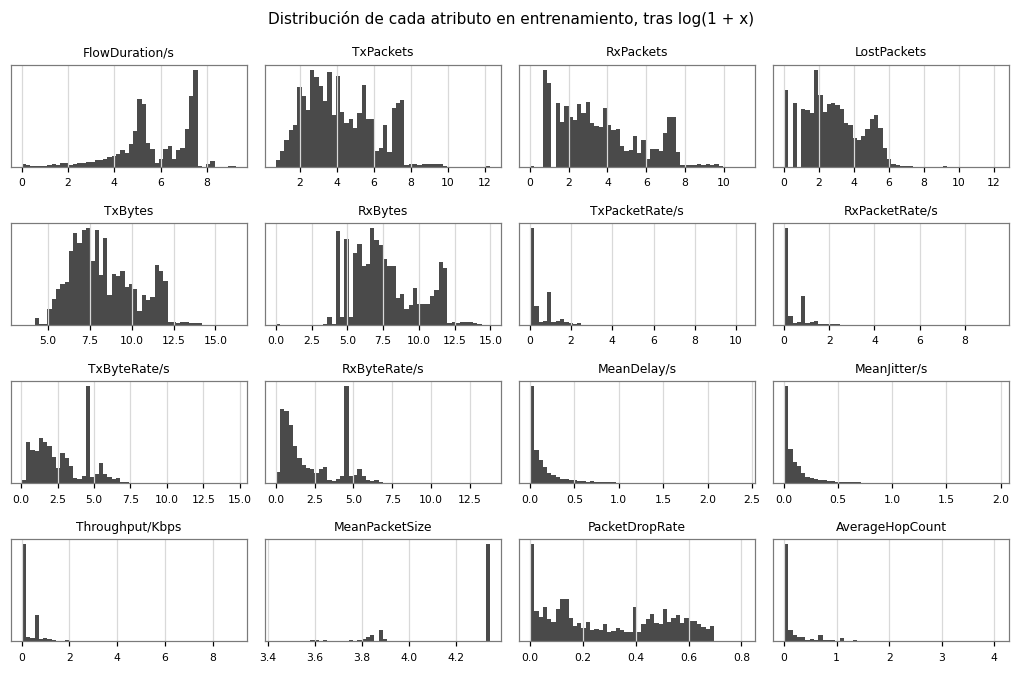

**Interpretación.** Las 6 columnas de conexión son categóricas o índices, y ya se excluyeron; los 16 atributos restantes son numéricos. Su asimetría es extrema: la mayor es de 163,4, en `TxByteRate/s`, y la mediana de esa asimetría entre atributos es de 29,4, con una mediana de 8,0 % de valores atípicos. Tras aplicar $\log(1 + x)$, la asimetría mediana baja a 0,54 y los atípicos a 0,2 %.

Esto significa que unos pocos flujos muy grandes dominarían el gradiente si se usaran las escalas originales, cuyos máximos llegan a 11 265 075. Además, varios histogramas tienen más de una moda, lo que apunta a mezclas de tipos de flujo.

Por tal motivo, se opta por transformar con $\log(1 + x)$, que conserva los ceros, y estandarizar después con la media y la desviación de entrenamiento.

**Decisión de preprocesamiento.** Recorte de `PacketDropRate` a 1, $\log(1 + x)$ en todos los atributos y estandarización ajustada solo con entrenamiento. No se eliminan atípicos, porque son flujos válidos y pueden ser la huella del ataque.

**Impacto en la arquitectura.** Con la entrada en escala comparable, un perceptrón multicapa no necesita capas de normalización para arrancar. No hay variables categóricas que codificar.

**Riesgos.** Ajustar la transformación con todo el archivo sería una fuga, y por eso solo se usa entrenamiento. Los atípicos pueden seguir pesando en modelos sin regularización.

In [13]:
def atipicos(valores):
    q1, q3 = np.percentile(valores, [25, 75])
    return float(100 * ((valores < q1 - 1.5 * (q3 - q1)) | (valores > q3 + 1.5 * (q3 - q1))).mean())


x_ent_crudo = x_crudo[id_ent]
filas = [{"Columna": c, "Tipo": "Categórica nominal" if c in ("SrcAddr", "DstAddr", "Protocol") else "Categórica de puerto" if c in ("SrcPort", "DstPort") else "Índice", "Cardinalidad": int(datos[c].nunique()), "Uso": "Excluida"} for c in IDENTIFICADORES]
display(pd.DataFrame(filas).style.hide(axis="index"))
estructura = pd.DataFrame([{"Atributo": c, "Valores distintos": len(np.unique(x_ent_crudo[:, j])), "Mediana": np.median(x_ent_crudo[:, j]), "Máximo": x_ent_crudo[:, j].max(), "Asimetría": stats.skew(x_ent_crudo[:, j]), "Curtosis": stats.kurtosis(x_ent_crudo[:, j]),
                            "% atípicos": atipicos(x_ent_crudo[:, j]), "Asimetría tras log": stats.skew(np.log1p(x_ent_crudo[:, j])), "% atípicos tras log": atipicos(np.log1p(x_ent_crudo[:, j]))} for j, c in enumerate(ATRIBUTOS)])
display(estructura.style.hide(axis="index").format(precision=3))
fig, ejes = plt.subplots(4, 4, figsize=(9.4, 6.2))
for eje, (j, c) in zip(ejes.ravel(), enumerate(ATRIBUTOS)):
    eje.hist(np.log1p(x_ent_crudo[:, j]), bins=50, color=GRIS_OSCURO)
    eje.set_title(c, fontsize=8)
    eje.set_yticks([])
    eje.tick_params(labelsize=7)
fig.suptitle("Distribución de cada atributo en entrenamiento, tras log(1 + x)", fontsize=10)
plt.tight_layout()
plt.show()
mas_asimetrico = estructura.loc[estructura["Asimetría"].idxmax()]
interpretar(f'''**Interpretación.** Las {len(IDENTIFICADORES)} columnas de conexión son categóricas o índices, y ya se excluyeron; los {len(ATRIBUTOS)} atributos restantes son numéricos. Su asimetría es extrema: la mayor es de {num(mas_asimetrico["Asimetría"], 1)}, en `{mas_asimetrico["Atributo"]}`, y la mediana de esa asimetría entre atributos es de {num(estructura["Asimetría"].median(), 1)}, con una mediana de {num(estructura["% atípicos"].median(), 1)} % de valores atípicos. Tras aplicar $\\log(1 + x)$, la asimetría mediana baja a {num(estructura["Asimetría tras log"].median(), 2)} y los atípicos a {num(estructura["% atípicos tras log"].median(), 1)} %.

Esto significa que unos pocos flujos muy grandes dominarían el gradiente si se usaran las escalas originales, cuyos máximos llegan a {num(estructura["Máximo"].max(), 0)}. Además, varios histogramas tienen más de una moda, lo que apunta a mezclas de tipos de flujo.

Por tal motivo, se opta por transformar con $\\log(1 + x)$, que conserva los ceros, y estandarizar después con la media y la desviación de entrenamiento.

**Decisión de preprocesamiento.** Recorte de `PacketDropRate` a 1, $\\log(1 + x)$ en todos los atributos y estandarización ajustada solo con entrenamiento. No se eliminan atípicos, porque son flujos válidos y pueden ser la huella del ataque.

**Impacto en la arquitectura.** Con la entrada en escala comparable, un perceptrón multicapa no necesita capas de normalización para arrancar. No hay variables categóricas que codificar.

**Riesgos.** Ajustar la transformación con todo el archivo sería una fuga, y por eso solo se usa entrenamiento. Los atípicos pueden seguir pesando en modelos sin regularización.''')

(sec-2-2-2)=
### 2.2.2 Relación entre atributos y objetivo

Se miden las correlaciones lineales y de rango entre atributos, la información mutua de cada atributo con la clase, para captar relaciones no lineales, y la multicolinealidad, con el factor de inflación de varianza, $VIF_j = 1 / (1 - R_j^2)$, y el número de condición de la matriz de correlación.

Atributo,Información mutua (nats),VIF
TxByteRate/s,"0,982","449,6"
FlowDuration/s,"0,934","82,6"
TxPacketRate/s,"0,932","24,8"
RxByteRate/s,"0,853","367,7"
Throughput/Kbps,"0,853","192,0"
TxBytes,"0,843","2,209,3"
RxPacketRate/s,"0,825","289,8"
PacketDropRate,"0,817","9,4"
RxBytes,"0,725","616,6"
TxPackets,"0,639","2,156,6"


|r| de Pearson,|ρ| de Spearman,Atributo,Atributo 2
"0,9940","0,9927",RxPackets,RxBytes
"0,9934","0,9899",RxPacketRate/s,Throughput/Kbps
"0,9928","0,9907",TxPackets,TxBytes
"0,9347","0,9112",TxPackets,RxPackets
"0,9313","0,9000",RxPackets,TxBytes
"0,9286","0,9028",TxBytes,RxBytes
"0,9212","0,9059",TxByteRate/s,RxByteRate/s
"0,9207","0,8990",TxPackets,RxBytes


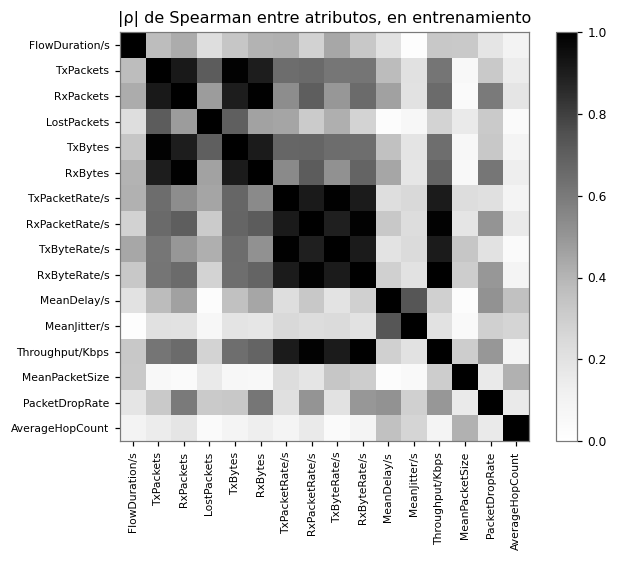

**Interpretación.** El atributo con más información sobre la clase es `TxByteRate/s`, con 0,982 nats, y el de menos es `MeanDelay/s`, con 0,231 nats, frente a una entropía de la clase de 1,604 nats. En multicolinealidad, el VIF llega a 2 209, el número de condición es de 190 y 0 pares tienen $|r|$ mayor que 0,999.

Esto se explica por la construcción de los atributos: las tasas son cocientes de los conteos sobre la duración, y, en la escala original, `Throughput/Kbps` equivale a `RxByteRate/s` en otras unidades. Es decir, varios atributos repiten la misma información, y los coeficientes de un modelo lineal no serían interpretables. Así mismo, ningún atributo alcanza por sí solo la entropía de la clase, de modo que la clasificación requiere combinarlos.

En ese sentido, se conservan los 16 atributos para los modelos de Deep Learning, porque la literatura usa los mismos y porque una red con regularización tolera la colinealidad, aunque sí se usa regularización L2 en el modelo lineal de referencia.

**Decisión de preprocesamiento.** No se eliminan atributos por colinealidad. No se detectan atributos derivados de la etiqueta entre los 16 que se conservan; los candidatos a fuga, `FlowID`, IP y puertos, ya se excluyeron en la sección {ref}`2.1.4 <sec-2-1-4>`.

**Impacto en la arquitectura.** La redundancia reduce la dimensión efectiva, de modo que no se justifican capas muy anchas y conviene la regularización. Además, el orden de los atributos no tiene significado físico, lo cual cuestiona el sesgo inductivo de los modelos que leen el vector como una secuencia.

**Riesgos.** La información mutua se estima sobre una muestra de 30 000 flujos y no capta interacciones entre atributos.

In [14]:
TOPE_TASA = np.where(np.array(ATRIBUTOS) == "PacketDropRate", 1.0, np.inf)


def transformar(matriz):
    return np.log1p(np.minimum(matriz, TOPE_TASA))


x_ent_log = transformar(x_ent_crudo)
pearson = np.corrcoef(x_ent_log, rowvar=False)
spearman = stats.spearmanr(x_ent_log).statistic
autovalores = np.linalg.eigvalsh(pearson)
condicion = float(np.sqrt(autovalores.max() / max(autovalores.min(), 1e-12)))
vif = np.diag(np.linalg.pinv(pearson))
rng_mi = np.random.default_rng(SEMILLA)
muestra_mi = rng_mi.permutation(len(id_ent))[:30000]
info_mutua = mutual_info_classif(x_ent_log[muestra_mi], y[id_ent][muestra_mi], random_state=SEMILLA)
relacion = pd.DataFrame({"Atributo": ATRIBUTOS, "Información mutua (nats)": info_mutua, "VIF": vif}).sort_values("Información mutua (nats)", ascending=False)
display(relacion.style.hide(axis="index").format({"Información mutua (nats)": "{:.3f}", "VIF": "{:,.1f}"}))
pares = sorted([(abs(pearson[i, j]), abs(spearman[i, j]), ATRIBUTOS[i], ATRIBUTOS[j]) for i in range(len(ATRIBUTOS)) for j in range(i + 1, len(ATRIBUTOS))], reverse=True)
display(pd.DataFrame(pares[:8], columns=["|r| de Pearson", "|ρ| de Spearman", "Atributo", "Atributo 2"]).style.hide(axis="index").format(precision=4))
fig, eje = plt.subplots(figsize=(6.2, 5.2))
imagen = eje.imshow(np.abs(spearman), vmin=0, vmax=1)
eje.set_xticks(range(len(ATRIBUTOS)), ATRIBUTOS, rotation=90, fontsize=7)
eje.set_yticks(range(len(ATRIBUTOS)), ATRIBUTOS, fontsize=7)
eje.grid(False)
eje.set_title("|ρ| de Spearman entre atributos, en entrenamiento")
fig.colorbar(imagen, fraction=0.046)
plt.tight_layout()
plt.show()
perfectos = [(a, b) for r, _, a, b in pares if r > 0.999]
interpretar(f'''**Interpretación.** El atributo con más información sobre la clase es `{relacion.iloc[0]["Atributo"]}`, con {num(relacion.iloc[0]["Información mutua (nats)"], 3)} nats, y el de menos es `{relacion.iloc[-1]["Atributo"]}`, con {num(relacion.iloc[-1]["Información mutua (nats)"], 3)} nats, frente a una entropía de la clase de {num(entropia * np.log(2), 3)} nats. En multicolinealidad, el VIF llega a {num(relacion["VIF"].max(), 0)}, el número de condición es de {num(condicion, 0)} y {len(perfectos)} pares tienen $|r|$ mayor que 0,999{", como `" + perfectos[0][0] + "` y `" + perfectos[0][1] + "`" if perfectos else ""}.

Esto se explica por la construcción de los atributos: las tasas son cocientes de los conteos sobre la duración, y, en la escala original, `Throughput/Kbps` equivale a `RxByteRate/s` en otras unidades. Es decir, varios atributos repiten la misma información, y los coeficientes de un modelo lineal no serían interpretables. Así mismo, ningún atributo alcanza por sí solo la entropía de la clase, de modo que la clasificación requiere combinarlos.

En ese sentido, se conservan los {len(ATRIBUTOS)} atributos para los modelos de Deep Learning, porque la literatura usa los mismos y porque una red con regularización tolera la colinealidad, aunque sí se usa regularización L2 en el modelo lineal de referencia.

**Decisión de preprocesamiento.** No se eliminan atributos por colinealidad. No se detectan atributos derivados de la etiqueta entre los {len(ATRIBUTOS)} que se conservan; los candidatos a fuga, `FlowID`, IP y puertos, ya se excluyeron en la sección 2.1.4.

**Impacto en la arquitectura.** La redundancia reduce la dimensión efectiva, de modo que no se justifican capas muy anchas y conviene la regularización. Además, el orden de los atributos no tiene significado físico, lo cual cuestiona el sesgo inductivo de los modelos que leen el vector como una secuencia.

**Riesgos.** La información mutua se estima sobre una muestra de 30 000 flujos y no capta interacciones entre atributos.''')

(sec-2-2-3)=
### 2.2.3 Complejidad de la tarea

Se ajusta una regresión logística con regularización L2 para estimar la separabilidad lineal y dimensionar el margen de mejora disponible. Esta es una referencia de contexto, no un modelo base, y el boosting de la sección {ref}`2.1.3 <sec-2-1-3>` se usa como referencia de lo que alcanza un modelo no lineal sin Deep Learning.

In [15]:
MEDIA = transformar(x_crudo[id_ent]).mean(0)
DESVIACION = transformar(x_crudo[id_ent]).std(0)
X_std = (transformar(x_crudo) - MEDIA) / DESVIACION
logistico = LogisticRegression(C=1.0, max_iter=3000).fit(X_std[id_ent], y[id_ent])
pred_log = logistico.predict(X_std[id_val])
f1_log_val = f1_score(y[id_val], pred_log, average="macro")
f1_log_ent = f1_score(y[id_ent], logistico.predict(X_std[id_ent]), average="macro")
boosting = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA).fit(X_std[id_ent], y[id_ent])
pred_boost = boosting.predict(X_std[id_val])
complejidad = pd.DataFrame({"Clase": CLASES, "F1 logístico": f1_score(y[id_val], pred_log, average=None), "F1 boosting": f1_score(y[id_val], pred_boost, average=None)})
display(complejidad.style.hide(axis="index").format(precision=4))
f1_boost_val = f1_score(y[id_val], pred_boost, average="macro")
clase_lineal = complejidad.loc[complejidad["F1 logístico"].idxmin(), "Clase"]
margen_lineal = f1_boost_val - f1_log_val
gana_lineal = enumerar(complejidad.loc[complejidad["F1 logístico"] > complejidad["F1 boosting"], "Clase"])
gana_boosting = enumerar(complejidad.loc[complejidad["F1 boosting"] > complejidad["F1 logístico"], "Clase"])
interpretar(f'''**Interpretación.** En validación, la regresión logística obtiene un F1 macro de {num(f1_log_val, 4)}, con {num(f1_log_ent, 4)} en entrenamiento, y el boosting obtiene {num(f1_boost_val, 4)}. Por clase, el modelo lineal es mejor en {gana_lineal}, mientras que el boosting lo es en {gana_boosting}. La clase más difícil para el modelo lineal es {clase_lineal}, con F1 de {num(complejidad["F1 logístico"].min(), 3)}.

Esto significa que la tarea es en buena parte separable con una frontera lineal sobre los logaritmos, y que, en estos bloques de validación y sin ajustar el boosting, la no linealidad aporta {num(margen_lineal, 4)}, {"menos que" if margen_lineal < 0.01 else "más que"} el margen δ = 0,01. Es decir, el costo de una red no se justifica de antemano, y hay que comprobarlo sobre la prueba.

Por lo anterior, conviene usar el modelo logístico como piso de comparación de los modelos base en la sección 5.3.

**Decisión de preprocesamiento.** Se mantiene la transformación definida en la sección 2.2.1.

**Impacto en la arquitectura.** La distancia de {num(margen_lineal, 4)} entre el modelo lineal y el boosting indica que basta con pocas capas ocultas para capturar la no linealidad, y no justifica por sí sola una arquitectura profunda.

**Riesgos.** El boosting es una referencia de contexto; no compite como modelo base y sus hiperparámetros no se ajustaron.''')

Clase,F1 logístico,F1 boosting
Blackhole,"0,8283","0,8693"
Flooding,"0,8648","0,8144"
Normal,"0,9523","0,9901"
Sybil,"0,9652","0,8939"
Wormhole,"0,7905","0,8696"


**Interpretación.** En validación, la regresión logística obtiene un F1 macro de 0,8803, con 0,8875 en entrenamiento, y el boosting obtiene 0,8875. Por clase, el modelo lineal es mejor en Flooding y Sybil, mientras que el boosting lo es en Blackhole, Normal y Wormhole. La clase más difícil para el modelo lineal es Wormhole, con F1 de 0,791.

Esto significa que la tarea es en buena parte separable con una frontera lineal sobre los logaritmos, y que, en estos bloques de validación y sin ajustar el boosting, la no linealidad aporta 0,0072, menos que el margen δ = 0,01. Es decir, el costo de una red no se justifica de antemano, y hay que comprobarlo sobre la prueba.

Por lo anterior, conviene usar el modelo logístico como piso de comparación de los modelos base en la sección {ref}`5.3 <sec-5-3>`.

**Decisión de preprocesamiento.** Se mantiene la transformación definida en la sección {ref}`2.2.1 <sec-2-2-1>`.

**Impacto en la arquitectura.** La distancia de 0,0072 entre el modelo lineal y el boosting indica que basta con pocas capas ocultas para capturar la no linealidad, y no justifica por sí sola una arquitectura profunda.

**Riesgos.** El boosting es una referencia de contexto; no compite como modelo base y sus hiperparámetros no se ajustaron.

(sec-2-2-4)=
### 2.2.4 Implicaciones clave

Las decisiones de este bloque condicionan los modelos de la sección 4, y se resumen en cuatro puntos:

| Aspecto | Decisión | Sustento |
|---|---|---|
| Diseño del perceptrón multicapa | Pocas capas ocultas, de ancho moderado y con regularización | La dimensión efectiva es baja y el margen no lineal es acotado (secciones {ref}`2.2.2 <sec-2-2-2>` y {ref}`2.2.3 <sec-2-2-3>`) |
| Variables categóricas | No se usan | Las columnas categóricas funcionan como atajos (sección {ref}`2.1.4 <sec-2-1-4>`) |
| Función de pérdida | Entropía cruzada con pesos de clase | Al eliminar las filas repetidas, Flooding queda como clase minoritaria (secciones {ref}`2.1.2 <sec-2-1-2>` y {ref}`2.2.5 <sec-2-2-5>`) |
| Partición | Estratificada por clase y agrupada por bloques | Las filas vecinas no son independientes (sección {ref}`2.1.3 <sec-2-1-3>`) |

(sec-2-2-5)=
### 2.2.5 Preparación de los datos para entrenar

Con la transformación definida, los datos se guardan listos para entrenar, con la media y la desviación de entrenamiento y los pesos de clase, $w_c = n / (K n_c)$, que hacen que cada clase aporte lo mismo a la pérdida total, porque $n_c w_c = n / K$.

In [16]:
frecuencia = np.bincount(y[id_ent], minlength=K)
PESOS_CLASE = (frecuencia.sum() / (K * frecuencia)).astype(np.float32)
np.savez(RESULTADOS / "datos_preparados.npz", largo_bloque=LARGO_BLOQUE, X=X_std.astype(np.float32), y=y, media=MEDIA, desviacion=DESVIACION, pesos=PESOS_CLASE, atributos=np.array(ATRIBUTOS), clases=np.array(CLASES), tx_packets=datos["TxPackets"].to_numpy())
display(pd.DataFrame({"Clase": CLASES, "Entrenamiento": frecuencia, "Peso": PESOS_CLASE}).style.hide(axis="index").format({"Peso": "{:.3f}"}))
print(f"Datos preparados: {len(ATRIBUTOS)} atributos | entrenamiento {len(id_ent):,} | validación {len(id_val):,} | prueba {len(id_pru):,}")

Clase,Entrenamiento,Peso
Blackhole,17342,"0,845"
Flooding,7569,"1,936"
Normal,16698,"0,878"
Sybil,15085,"0,971"
Wormhole,16573,"0,884"


Datos preparados: 16 atributos | entrenamiento 73,267 | validación 17,802 | prueba 22,883
